# DANDI:001888 NWB Tutorial: EEG recordings from a Grin2b+/- rat model of GRIN2B neurodevelopmental disorder: absence seizures and sleep-wake abnormalities

This notebook demonstrates how to read and visualize the  Gonzalez-Sulser Lab dataset ([Hristova et al. 2025](https://doi.org/10.1111/epi.18606)). It covers:

1. Loading/Streaming the NWB file and inspecting top-level metadata
2. Reading raw EEG/EMG acquisition data
3. Full-recording EEG spectrogram
4. Reading sleep-state epoch annotations
5. Sleep states by hour
6. Reading per-sleep-state power spectra
7. Reading seizure event intervals
8. EEG/EMG around a seizure event
9. Reading per-epoch spike-wave discharge (SWD) counts
10. Accessing external ontology resources (HERD)

The notebook has two ways to get an `nwbfile` to work with. Pick whichever fits your
workflow:

1. **Stream directly from DANDI**, no download needed, works anywhere.
2. **Read a local NWB file**, fastest if you already have the file on disk (e.g. from
   the lab's data share), and lets us also open the companion video files.

Everything after that (file structure exploration and visualizations) works the same
regardless of which source you used.

## Setup

```bash
pip install dandi pynwb remfile h5py matplotlib pandas
```


In [1]:
# Core data manipulation and analysis
from pathlib import Path

import h5py

# Visualization
import matplotlib.pyplot as plt
import numpy as np
import remfile
from dandi.dandiapi import DandiAPIClient

# NWB and DANDI access
from pynwb import NWBHDF5IO

# Configure matplotlib
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

## Data Access Functions

### Stream a session directly from DANDI

DANDI assets can be read directly over HTTP with [`remfile`](https://github.com/flatironinstitute/remfile),
without downloading the file to disk. This is the easiest way to explore the dataset if
you don't already have it locally.

We'll stream one session from **[DANDI:001888](https://dandiarchive.org/dandiset/001888)**.
Swap `dandiset_id` / `file_path` for any other subject/session in the Dandiset — use
`dandiset.get_assets()` to list them all.

In [2]:
def load_nwb_from_dandi(dandiset_id, subject_id, session_id, modality):
    """
    Load NWB file from DANDI Archive via streaming.
    """
    pattern = f"sub-{subject_id}/sub-{subject_id}_ses-{session_id}_{modality}*.nwb"

    with DandiAPIClient() as client:
        client.dandi_authenticate()
        assets = client.get_dandiset(dandiset_id, "draft").get_assets_by_glob(
            pattern=pattern, order="path"
        )

        s3_urls = []
        for asset in assets:
            s3_url = asset.get_content_url(follow_redirects=1, strip_query=False)
            s3_urls.append(s3_url)

        if len(s3_urls) != 1:
            raise ValueError(
                f"Expected 1 file, found {len(s3_urls)} for pattern {pattern}"
            )

        s3_url = s3_urls[0]

    file = remfile.File(s3_url)
    h5_file = h5py.File(file, "r")
    io = NWBHDF5IO(file=h5_file, load_namespaces=True)
    nwbfile = io.read()

    return nwbfile, io

### Read a local NWB file

If the file is already on disk (e.g. mounted from the lab's data share), reading it is
just a standard `NWBHDF5IO` call.

In [3]:
def load_nwb_local(directory_path, subject_id, session_id, modality):
    """
    Load NWB file from local directory.
    """
    directory_path = Path(directory_path)
    nwbfile_path = directory_path / f"sub-{subject_id}_ses-{session_id}_{modality}.nwb"

    if not nwbfile_path.exists():
        raise FileNotFoundError(f"NWB file not found: {nwbfile_path}")

    io = NWBHDF5IO(path=nwbfile_path, load_namespaces=True)
    nwbfile = io.read()

    return nwbfile, io

## 1. Load and inspect top-level metadata

### Choose which source to explore

In [4]:
# Choose data source (DANDI streaming or local)
USE_DANDI = False # Set to False to use local files
dandiset_id = "001888"
subject_id = "GRIN2B-129"
session_id = "2021-03-26"
modality = "ecephys"
if USE_DANDI:
    nwbfile, io = load_nwb_from_dandi(dandiset_id, subject_id, session_id, modality)
else:
    # Specify your local directory path
    local_directory = f"H:/{dandiset_id}/sub-{subject_id}"  # Replace with actual path
    local_directory = f"H:/gonzalez-nwbfiles/sub-{subject_id}"
    nwbfile, io = load_nwb_local(local_directory, subject_id, session_id, modality)
    

In [5]:
print("=== SESSION INFORMATION ===")
print(f"Session description: {nwbfile.session_description}")
print(f"Session start time: {nwbfile.session_start_time}")
print(f"Experiment description: {nwbfile.experiment_description}")

=== SESSION INFORMATION ===
Session description: Chronic wireless EEG/EMG recording, subject GRIN2B_129, full raw recording with BL1 and BL2 24-h baseline window(s) marked in the NWB epochs table. 
Session start time: 2021-03-26 10:56:00+00:00
Experiment description: Chronic wireless EEG and EMG recordings from freely behaving Long-Evans rats carrying a heterozygous knockout of Grin2b (Grin2b+/-), the gene encoding the GluN2B subunit of N-methyl-D-aspartate receptors (NMDARs). Grin2b+/- rats display spontaneous spike-and-wave discharges (SWDs, the electrographic correlate of absence seizures) at higher incidence and duration than wild-type littermates, alongside reduced REM sleep and altered NREM/wake distributions. Recordings were acquired over 72-96 h using the TaiNi wireless multichannel recording system (Tainitec, UK) with 14-channel skull-surface EEG electrode grids and bilateral neck EMG electrodes, at 250.4 Hz. Two consecutive 24-h baseline windows (BL1, BL2) were extracted per 

In [6]:
print(f"Session ID:          {nwbfile.session_id}")
print(f"Session start time:  {nwbfile.session_start_time}")
print(f"Institution:         {nwbfile.institution}")
print(f"Lab:                 {nwbfile.lab}")
print(f"Subject ID:          {nwbfile.subject.subject_id}")
print(f"Subject species:     {nwbfile.subject.species}")
print()
print("Acquisition keys:", list(nwbfile.acquisition.keys()))
print("Processing modules:", list(nwbfile.processing.keys()))

epochs_df = nwbfile.epochs.to_dataframe()
print()
print(
    "Baseline windows 1 and 2 are marked in the NWB epochs table (seconds relative to session_start_time)"
)
epochs_df[:]
bl1_start_time = epochs_df["start_time"][0]
bl2_start_time = epochs_df["start_time"][1]

Session ID:          2021-03-26
Session start time:  2021-03-26 10:56:00+00:00
Institution:         University of Edinburgh
Lab:                 Gonzalez-Sulser Lab
Subject ID:          GRIN2B-129
Subject species:     Rattus norvegicus

Acquisition keys: ['EEGElectricalSeries', 'EMGElectricalSeries']
Processing modules: ['behavior', 'ecephys']

Baseline windows 1 and 2 are marked in the NWB epochs table (seconds relative to session_start_time)


In [7]:
nwbfile

root pynwb.file.NWBFile at 0x1721686946704
Fields:
  acquisition: {
    EEGElectricalSeries <class 'pynwb.ecephys.ElectricalSeries'>,
    EMGElectricalSeries <class 'pynwb.ecephys.ElectricalSeries'>
  }
  device_models: {
    TainiTec wireless EEG and EMG transmitter <class 'pynwb.device.DeviceModel'>
  }
  devices: {
    TainiTecWirelessEEG <class 'pynwb.device.Device'>
  }
  electrode_groups: {
    EEGArray <class 'pynwb.ecephys.ElectrodeGroup'>,
    EMGArray <class 'pynwb.ecephys.ElectrodeGroup'>
  }
  electrodes: electrodes <class 'pynwb.ecephys.ElectrodesTable'>
  epochs: epochs <class 'pynwb.epoch.TimeIntervals'>
  experiment_description: Chronic wireless EEG and EMG recordings from freely behaving Long-Evans rats carrying a heterozygous knockout of Grin2b (Grin2b+/-), the gene encoding the GluN2B subunit of N-methyl-D-aspartate receptors (NMDARs). Grin2b+/- rats display spontaneous spike-and-wave discharges (SWDs, the electrographic correlate of absence seizures) at higher incidence and duration than wild-type littermates, alongside reduced REM sleep and altered NREM/wake distributions. Recordings were acquired over 72-96 h using the TaiNi wireless multichannel recording system (Tainitec, UK) with 14-channel skull-surface EEG electrode grids and bilateral neck EMG electrodes, at 250.4 Hz. Two consecutive 24-h baseline windows (BL1, BL2) were extracted per animal. Automated pipelines classified sleep states (Wake, NREM, REM) in 5-s epochs and detected SWD seizure events. Data contribute to the SFARI Autism Rat Models Consortium (ARC). See Hristova et al., Epilepsia 2025 (doi:10.1111/epi.18606).

  experimenter: ['Hristova, Katerina' 'Fasol, Melissa C. M.' 'McLaughlin, Niamh'
 'Nawaz, Mohammad Sarfaraz' 'Taskiran, Mehmet' 'Buller-Peralta, Ingrid'
 'Harris, Anjanette P.' 'Sutherland, Andrew' 'Bassi, Alejandro'
 'Ocampo-Garces, Adrian' 'Escudero, Javier' 'Kind, Peter C.'
 'Gonzalez-Sulser, Alfredo']
  external_resources: external_resources hdmf.common.resources.HERD at 0x1721687312784
  13 key(s), 10 entity(ies), 6 object(s), 1 file(s)
                          file_object_id  objects_idx  \
0   686fefda-77ee-440e-87d6-02cb62bf815c            0   
1   686fefda-77ee-440e-87d6-02cb62bf815c            1   
2   686fefda-77ee-440e-87d6-02cb62bf815c            2   
3   686fefda-77ee-440e-87d6-02cb62bf815c            3   
4   686fefda-77ee-440e-87d6-02cb62bf815c            3   
5   686fefda-77ee-440e-87d6-02cb62bf815c            3   
6   686fefda-77ee-440e-87d6-02cb62bf815c            3   
7   686fefda-77ee-440e-87d6-02cb62bf815c            3   
8   686fefda-77ee-440e-87d6-02cb62bf815c            3   
9   686fefda-77ee-440e-87d6-02cb62bf815c            3   
10  686fefda-77ee-440e-87d6-02cb62bf815c            3   
11  686fefda-77ee-440e-87d6-02cb62bf815c            4   
12  686fefda-77ee-440e-87d6-02cb62bf815c            5   

                               object_id  files_idx     object_type  \
0   b0169b2f-2e74-4857-b795-28091ed5a0ea          0         Subject   
1   b0169b2f-2e74-4857-b795-28091ed5a0ea          0         Subject   
2   b0169b2f-2e74-4857-b795-28091ed5a0ea          0         Subject   
3   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
4   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
5   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
6   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
7   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
8   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
9   f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
10  f2f1b8cb-e780-4256-96cc-67ce3aa4d45f          0      VectorData   
11  301bcda2-9427-4c55-8aec-631da44ba7cb          0  ElectrodeGroup   
12  9f575e33-0836-4cc7-b881-b8b56632aa7f          0  ElectrodeGroup   

   relative_path field  keys_idx                key  entities_idx  \
0        species               0  Rattus norvegicus           

## 2. Raw EEG / EMG

The full 24 h recording is stored as **two** `ElectricalSeries` in `acquisition` - one for
EEG, one for EMG - sharing a single electrode table but linked to distinct `ElectrodeGroup`s:

- `EEGElectricalSeries{baseline_name}`: **14 EEG channels** - bilateral cortex - S1_Tr, M2_Fra, M2_anterior, M1_anterior, V2_ML, V1_M, S1Hl_S1Fl (Right + Left)
- `EMGElectricalSeries{baseline_name}`: **2 EMG channels** - Right and Left


In [8]:
eeg_name = next(name for name in nwbfile.acquisition if name.startswith("EEGElectricalSeries"))
emg_name = next(name for name in nwbfile.acquisition if name.startswith("EMGElectricalSeries"))
eeg_es = nwbfile.acquisition[eeg_name]
emg_es = nwbfile.acquisition[emg_name]

for name, es in [("EEG", eeg_es), ("EMG", emg_es)]:
    print(f"--- {name} ---")
    print(f"ElectricalSeries shape:  {es.data.shape}")
    print(f"Sampling rate:           {es.rate} Hz")
    print(
        f"Starting time:           {es.starting_time:.2f} s (= session_start_time; full recording)"
    )
    print(f"Duration:                {es.data.shape[0] / es.rate / 3600:.2f} h")
    print(f"Conversion (to volts):   {es.conversion:.6e}")
    print()

electrodes = nwbfile.electrodes.to_dataframe()
electrodes[:]

--- EEG ---
ElectricalSeries shape:  (69391534, 14)
Sampling rate:           250.4 Hz
Starting time:           0.00 s (= session_start_time; full recording)
Duration:                76.98 h
Conversion (to volts):   3.174603e-06

--- EMG ---
ElectricalSeries shape:  (69391534, 2)
Sampling rate:           250.4 Hz
Starting time:           0.00 s (= session_start_time; full recording)
Duration:                76.98 h
Conversion (to volts):   3.174603e-06



,location,group,group_name,channel_name,filtering,hemisphere,rel_x,rel_y
id,,,,,,,,
0,S1_Tr,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,S1_Tr_R,none,R,-3.0,2.8
1,M2_Fra,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,M2_Fra_R,none,R,3.6,1.2
2,M2_anterior,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,M2_anterior_R,none,R,1.5,1.2
3,M1_anterior,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,M1_anterior_R,none,R,1.5,2.8
4,V2_ML,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,V2_ML_R,none,R,-5.0,3.0
5,V1_M,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,V1_M_R,none,R,-7.0,3.0
6,S1Hl_S1Fl,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,S1Hl_S1Fl_R,none,R,-1.0,2.8
7,V1_M,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,V1_M_L,none,L,-7.0,3.0
8,V2_ML,EEGArray pynwb.ecephys.ElectrodeGroup at 0x172...,EEGArray,V2_ML_L,none,L,-5.0,3.0


### Electrode layout on the skull

`rel_x`/`rel_y` in the electrode table are stereotaxic coordinates relative to bregma
(in mm): `rel_x` is the antero-posterior (AP) offset (positive = anterior) and `rel_y` is
the medio-lateral (ML) distance from the midline, with `hemisphere` (`R`/`L`) giving the
sign. The schematic below plots the 14 EEG electrodes at these positions on a simplified
rat skull outline.

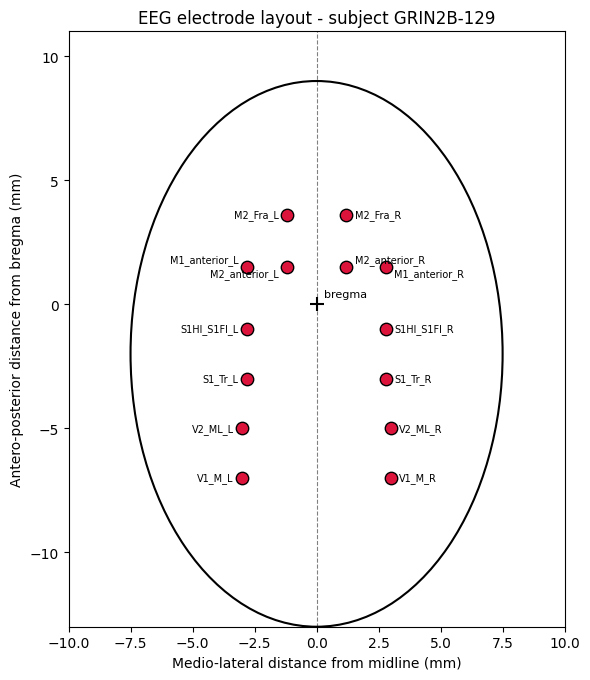

In [9]:
from matplotlib.patches import Ellipse

# Only the 14 EEG electrodes carry stereotaxic coordinates (EMG rows are NaN)
eeg_electrodes = electrodes.dropna(subset=["rel_x", "rel_y"])

# AP = rel_x (anterior positive); ML = rel_y, signed by hemisphere (R positive, L negative)
ap = eeg_electrodes["rel_x"].to_numpy()
ml = eeg_electrodes["rel_y"].to_numpy() * np.where(
    eeg_electrodes["hemisphere"].to_numpy() == "R", 1, -1
)
names = eeg_electrodes["channel_name"].to_numpy()

fig, ax = plt.subplots(figsize=(6, 8))

# Simplified rat skull outline (bregma at the origin)
skull = Ellipse(
    (0, -2), width=15, height=22, facecolor="none", edgecolor="black", lw=1.5
)
ax.add_patch(skull)
ax.axvline(0, color="gray", lw=0.8, ls="--", zorder=0)  # sagittal suture
ax.plot(0, 0, "+", color="black", ms=10, mew=1.5)  # bregma
ax.annotate("bregma", (0, 0), xytext=(0.3, 0.3), fontsize=8)

ax.scatter(ml, ap, s=80, c="crimson", edgecolor="black", zorder=3)

# Stagger labels vertically among electrodes that share (nearly) the same AP
# coordinate, so closely spaced markers (e.g. M1_anterior/M2_anterior) don't collide
order = np.argsort(ap)
dy_by_point = np.zeros(len(ap))
for group_start in range(len(order)):
    i = order[group_start]
    same_ap = [j for j in order if abs(ap[j] - ap[i]) < 0.5 and np.sign(ml[j]) == np.sign(ml[i])]
    rank = same_ap.index(i)
    dy_by_point[i] = (rank - (len(same_ap) - 1) / 2) * 10

for x, y, name, dy in zip(ml, ap, names, dy_by_point):
    dx = 6 if x >= 0 else -6
    ha = "left" if x >= 0 else "right"
    ax.annotate(
        name,
        (x, y),
        textcoords="offset points",
        xytext=(dx, dy),
        ha=ha,
        va="center",
        fontsize=7,
    )

ax.set_xlabel("Medio-lateral distance from midline (mm)")
ax.set_ylabel("Antero-posterior distance from bregma (mm)")
ax.set_title(f"EEG electrode layout - subject {nwbfile.subject.subject_id}")
ax.set_aspect("equal")
ax.set_xlim(-10, 10)
ax.set_ylim(-13, 11)
plt.tight_layout()
plt.show()

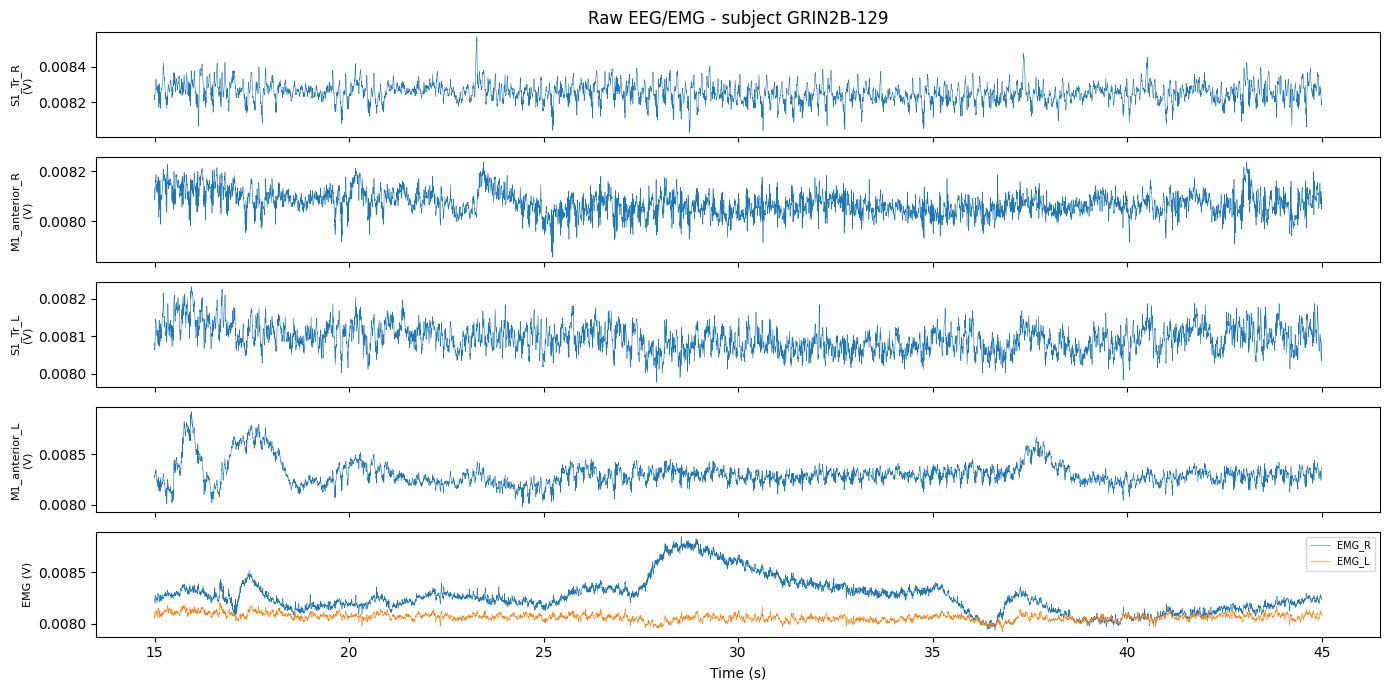

In [10]:
fs = eeg_es.rate
window_start_s = 15
window_duration_s = 30
window_end_s = window_start_s + window_duration_s

i_start = int(window_start_s * fs)
i_end = int(window_end_s * fs)

# Convert raw int16 ADC counts to volts using the confirmed TainiTec gain
# (es.conversion is in volts/count). The full recording is indexed directly
eeg_slice = eeg_es.data[i_start:i_end, :] * eeg_es.conversion  # lazy HDF5 read
emg_slice = emg_es.data[i_start:i_end, :] * emg_es.conversion  # lazy HDF5 read

t = eeg_es.get_timestamps()[i_start:i_end]

# EEG channels: indices within EEGElectricalSeries (14 channels) — pick a bilateral pair
eeg_idx = {"S1_Tr_R": 0, "M1_anterior_R": 3, "S1_Tr_L": 13, "M1_anterior_L": 10}
# EMG channels: indices within EMGElectricalSeries (2 channels)
emg_idx = {"EMG_R": 0, "EMG_L": 1}

fig, axes = plt.subplots(len(eeg_idx) + 1, 1, figsize=(14, 7), sharex=True)

for ax, (label, idx) in zip(axes[:-1], eeg_idx.items()):
    ax.plot(t, eeg_slice[:, idx], lw=0.4)
    ax.set_ylabel(f"{label}\n(V)", fontsize=8)

ax_emg = axes[-1]
for label, idx in emg_idx.items():
    ax_emg.plot(t, emg_slice[:, idx], lw=0.4, label=label)
ax_emg.set_ylabel("EMG (V)", fontsize=8)
ax_emg.legend(fontsize=7, loc="upper right")
ax_emg.set_xlabel(f"Time (s)")

axes[0].set_title(f"Raw EEG/EMG - subject {nwbfile.subject.subject_id}")
plt.tight_layout()
plt.show()

## 3. EEG spectrogram

Reproduces the lab's per-epoch spectrogram plot (`spec_129_BL2.png`): raw EEG power is
computed in the same 5-s epochs as the sleep scoring, then split into fixed-duration
panels stacked top-to-bottom to cover the full recording.

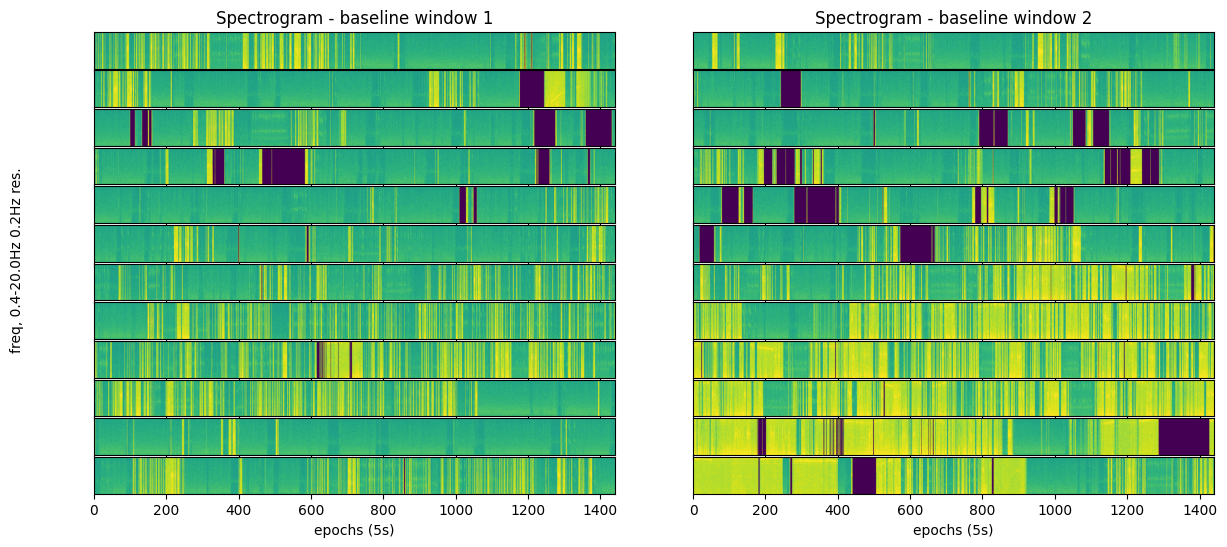

In [11]:
# ── Spectrogram parameters ────────────────────────────────────────────────────
channel_idx = 0  # EEG channel to use (index into eeg_es channels)
freq_min, freq_max = 0.4, 20.0  # Hz - matches the lab's plotting band
panel_duration_h = 2.0  # hours of recording per stacked panel
# ──────────────────────────────────────────────────────────────────────────────

fs = eeg_es.rate
epoch_len_s = 5.0  # same epoch length as the sleep scoring (Section 4)
n_per_epoch = int(round(epoch_len_s * fs))

baseline_windows = [
    ("baseline window 1", bl1_start_time, epochs_df["stop_time"][0]),
    ("baseline window 2", bl2_start_time, epochs_df["stop_time"][1]),
]

freqs = np.fft.rfftfreq(n_per_epoch, d=1 / fs)
freq_mask = (freqs >= freq_min) & (freqs <= freq_max)
freqs = freqs[freq_mask]

log_powers = []
for label, start_s, stop_s in baseline_windows:
    i_start = int(start_s * fs)
    i_stop = int(stop_s * fs)
    n_epochs = (i_stop - i_start) // n_per_epoch

    eeg_channel = eeg_es.data[
        i_start : i_start + n_epochs * n_per_epoch, channel_idx
    ]* eeg_es.conversion
    epochs = eeg_channel.reshape(n_epochs, n_per_epoch)

    power = np.abs(np.fft.rfft(epochs, axis=1)) ** 2
    log_power = np.log10(power[:, freq_mask] + np.finfo(float).eps)
    log_powers.append((label, log_power))

epochs_per_panel = int(panel_duration_h * 3600 / epoch_len_s)
n_panels = max(
    int(np.ceil(log_power.shape[0] / epochs_per_panel)) for _, log_power in log_powers
)
vmin, vmax = np.percentile(
    np.concatenate([lp for _, lp in log_powers], axis=0), [1, 99]
)

fig, axes = plt.subplots(
    n_panels, 2, figsize=(14, 0.5 * n_panels), sharex=True, squeeze=False
)
for col, (label, log_power) in enumerate(log_powers):
    n_epochs = log_power.shape[0]
    for panel in range(n_panels):
        ax = axes[panel, col]
        i0 = panel * epochs_per_panel
        i1 = min(i0 + epochs_per_panel, n_epochs)
        if i0 >= n_epochs:
            ax.axis("off")
            continue
        ax.imshow(
            log_power[i0:i1].T,
            aspect="auto",
            origin="lower",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            extent=[0, i1 - i0, freq_min, freq_max],
        )
        ax.set_yticks([])
    axes[0, col].set_title(f"Spectrogram - {label}")
    axes[-1, col].set_xlabel("epochs (5s)")

fig.text(
    0.04,
    0.5,
    f"freq, {freq_min}-{freq_max}Hz 0.2Hz res.",
    va="center",
    rotation="vertical",
)
plt.subplots_adjust(hspace=0.05, wspace=0.15, left=0.1)
plt.show()

## 4. Sleep-state epochs

5-second scored epochs are stored in a single merged table,
`processing/behavior/sleep_states`, spanning all baseline windows. A
`baseline_window` column (matching the tags in `nwbfile.epochs`) identifies which
baseline window each row belongs to.
State codes: 0 = Wake, 1 = NREM, 2 = REM. State 4 = SWD

In [12]:
behavior = nwbfile.processing["behavior"]
sleep_df = behavior["sleep_states"].to_dataframe()
sleep_df_bl1 = sleep_df[sleep_df["baseline_window"] == "baseline_window_1"]
sleep_df_bl2 = sleep_df[sleep_df["baseline_window"] == "baseline_window_2"]

In [13]:
print(
    f"Sleep epochs in the baseline window 1: {len(sleep_df_bl1)} rows (expected 17,280 for full 24 h)"
)
sleep_df_bl1[:]

Sleep epochs in the baseline window 1: 17280 rows (expected 17,280 for full 24 h)


,start_time,stop_time,sleep_score,sleep_state,baseline_window
id,,,,,
0,72240.0,72245.0,0,Wake,baseline_window_1
1,72245.0,72250.0,0,Wake,baseline_window_1
2,72250.0,72255.0,0,Wake,baseline_window_1
3,72255.0,72260.0,0,Wake,baseline_window_1
4,72260.0,72265.0,0,Wake,baseline_window_1
...,...,...,...,...,...
17275,158615.0,158620.0,1,NREM,baseline_window_1
17276,158620.0,158625.0,1,NREM,baseline_window_1
17277,158625.0,158630.0,1,NREM,baseline_window_1


In [14]:
print(
    f"Sleep epochs in the baseline window 2: {len(sleep_df_bl2)} rows (expected 17,280 for full 24 h)"
)
sleep_df_bl2[:]

Sleep epochs in the baseline window 2: 17280 rows (expected 17,280 for full 24 h)


,start_time,stop_time,sleep_score,sleep_state,baseline_window
id,,,,,
17280,158640.0,158645.0,1,NREM,baseline_window_2
17281,158645.0,158650.0,1,NREM,baseline_window_2
17282,158650.0,158655.0,1,NREM,baseline_window_2
17283,158655.0,158660.0,1,NREM,baseline_window_2
17284,158660.0,158665.0,1,NREM,baseline_window_2
...,...,...,...,...,...
34555,245015.0,245020.0,0,Wake,baseline_window_2
34556,245020.0,245025.0,0,Wake,baseline_window_2
34557,245025.0,245030.0,0,Wake,baseline_window_2


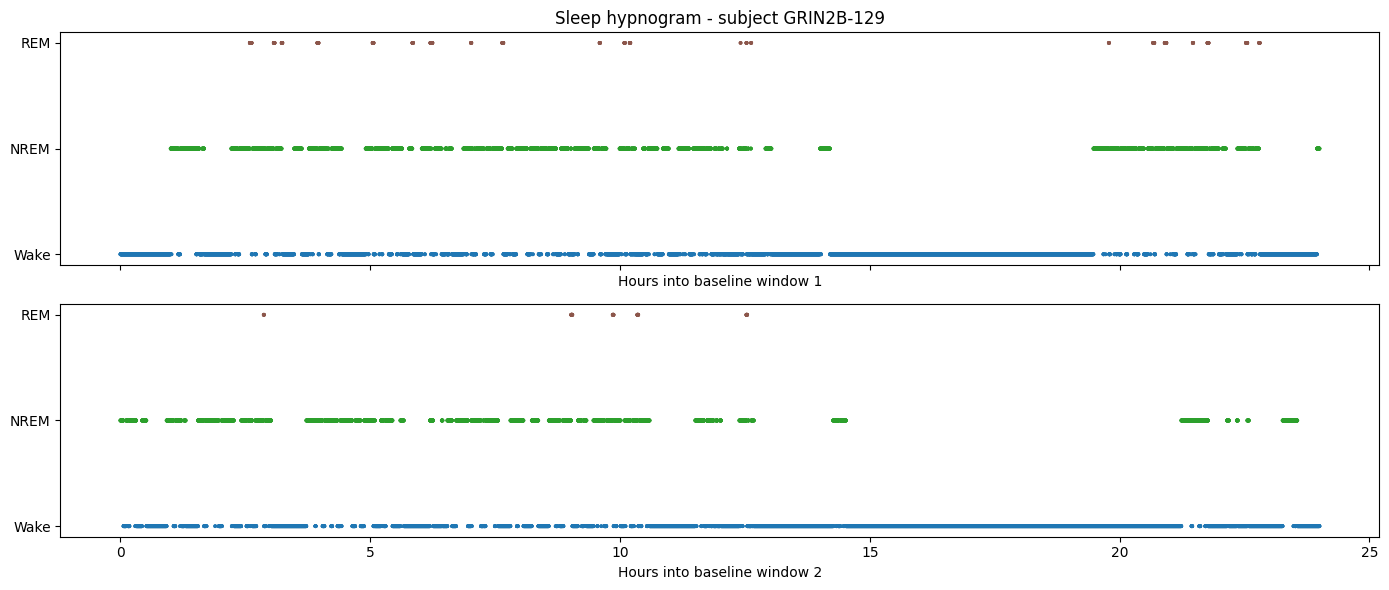

In [15]:
# Sleep hypnogram
state_labels = {0: "Wake", 1: "NREM", 2: "REM", 4: "SWD"}
t_mid = (sleep_df_bl1["start_time"] + sleep_df_bl1["stop_time"]) / 2
hours = (t_mid - bl1_start_time) / 3600  # hours into BL1 window

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].scatter(
    hours,
    sleep_df_bl1["sleep_score"],
    s=3,
    c=sleep_df_bl1["sleep_score"],
    cmap="tab10",
    vmin=0,
    vmax=4,
)
axes[0].set_yticks([0, 1, 2])
axes[0].set_yticklabels(["Wake", "NREM", "REM"])
axes[0].set_xlabel("Hours into baseline window 1")
axes[1].scatter(
    hours,
    sleep_df_bl2["sleep_score"],
    s=3,
    c=sleep_df_bl2["sleep_score"],
    cmap="tab10",
    vmin=0,
    vmax=4,
)
axes[1].set_yticks([0, 1, 2])
axes[1].set_yticklabels(["Wake", "NREM", "REM"])
axes[1].set_xlabel("Hours into baseline window 2")
axes[0].set_title(f"Sleep hypnogram - subject {nwbfile.subject.subject_id}")
plt.tight_layout()
plt.show()

## 5. Sleep states by hour

Stacked bar chart of epoch counts per hour since lights-on, reproducing the lab's
`States by Hour` plot (e.g. `sbh_129_BL1.png`).

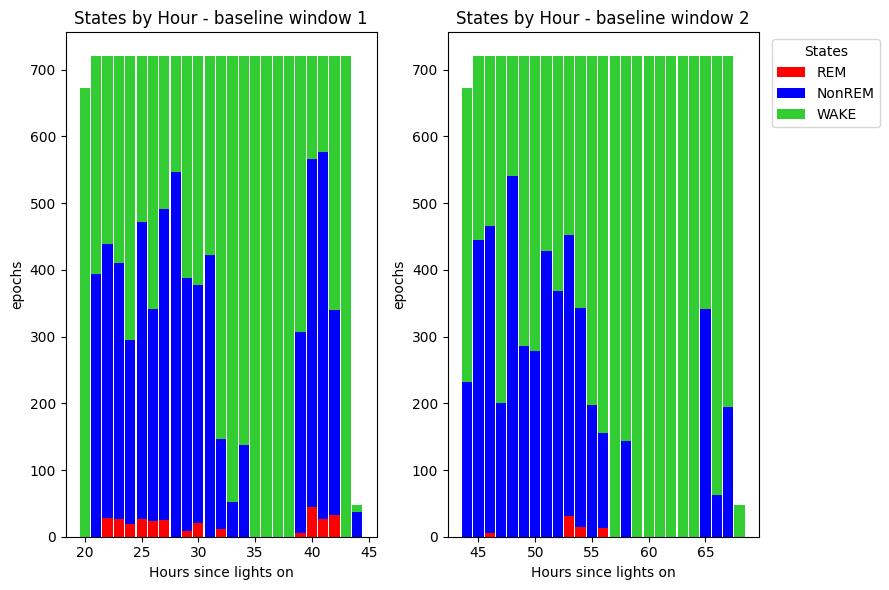

In [16]:
state_names = {0: "WAKE", 1: "NonREM", 2: "REM"}

# Bin each 5-s epoch into the hour (since lights-on / BL window start) it falls in
hours_since_lights_on_bl1 = np.floor(
    (sleep_df_bl1["start_time"] - eeg_es.starting_time) / 3600
).astype(int)

counts_by_hour_bl1 = (
    sleep_df_bl1["sleep_score"]
    .map(state_names)
    .groupby(hours_since_lights_on_bl1)
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=["REM", "NonREM", "WAKE"], fill_value=0)
    .sort_index()
)

hours_since_lights_on_bl2 = np.floor(
    (sleep_df_bl2["start_time"] - eeg_es.starting_time) / 3600
).astype(int)

counts_by_hour_bl2 = (
    sleep_df_bl2["sleep_score"]
    .map(state_names)
    .groupby(hours_since_lights_on_bl2)
    .value_counts()
    .unstack(fill_value=0)
    .reindex(columns=["REM", "NonREM", "WAKE"], fill_value=0)
    .sort_index()
)

fig, axes = plt.subplots(1,2, figsize=(9, 6))
bottom = np.zeros(len(counts_by_hour_bl1))
colors = {"WAKE": "limegreen", "NonREM": "blue", "REM": "red"}
for state in ["REM", "NonREM", "WAKE"]:
    axes[0].bar(
        counts_by_hour_bl1.index,
        counts_by_hour_bl1[state],
        bottom=bottom,
        width=0.9,
        color=colors[state],
        label=state,
    )
    bottom += counts_by_hour_bl1[state].to_numpy()

axes[0].set_xlabel("Hours since lights on")
axes[0].set_ylabel("epochs")
axes[0].set_title("States by Hour - baseline window 1")

bottom = np.zeros(len(counts_by_hour_bl2))
colors = {"WAKE": "limegreen", "NonREM": "blue", "REM": "red"}
for state in ["REM", "NonREM", "WAKE"]:
    axes[1].bar(
        counts_by_hour_bl2.index,
        counts_by_hour_bl2[state],
        bottom=bottom,
        width=0.9,
        color=colors[state],
        label=state,
    )
    bottom += counts_by_hour_bl2[state].to_numpy()

axes[1].set_xlabel("Hours since lights on")
axes[1].set_ylabel("epochs")
axes[1].set_title("States by Hour - baseline window 2")
axes[1].legend(title="States", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Per-sleep-state power spectra

628 frequency bins per baseline window (0→125.2 Hz, 0.2 Hz steps = Nyquist of 250.4 Hz),
stored in a single table, `processing/ecephys/sleep_state_power_spectra`. Columns
are named after the brain state: `Wake`, `NREM`, `REM`, `SWD`; a `baseline_window` column
identifies which baseline window each row belongs to.

In [17]:
ecephys = nwbfile.processing["ecephys"]
psd_df = ecephys["sleep_state_power_spectra"].to_dataframe()
psd_df_bl1 = psd_df[psd_df["baseline_window"] == "baseline_window_1"]
psd_df_bl2 = psd_df[psd_df["baseline_window"] == "baseline_window_2"]

In [18]:
print(f"PSD table: {psd_df_bl1.shape}")
psd_df_bl1[:]

PSD table: (627, 6)


,frequency_hz,Wake,NREM,REM,SWD,baseline_window
id,,,,,,
0,0.0,0.519809,0.539314,0.123515,0.634967,baseline_window_1
1,0.2,0.497687,0.535483,0.108808,0.614226,baseline_window_1
2,0.4,0.483442,0.558114,0.093001,0.598746,baseline_window_1
3,0.6,0.453522,0.574946,0.070813,0.554426,baseline_window_1
4,0.8,0.439977,0.590124,0.068346,0.537512,baseline_window_1
...,...,...,...,...,...,...
622,124.4,0.042762,0.004024,0.005191,0.070005,baseline_window_1
623,124.6,0.042678,0.004111,0.005180,0.070263,baseline_window_1
624,124.8,0.042597,0.004328,0.005418,0.070568,baseline_window_1


In [19]:
print(f"PSD table: {psd_df_bl2.shape}")
psd_df_bl2[:]

PSD table: (627, 6)


,frequency_hz,Wake,NREM,REM,SWD,baseline_window
id,,,,,,
627,0.0,0.864452,0.935737,0.533670,1.050656,baseline_window_2
628,0.2,0.875762,0.965950,0.550871,1.060105,baseline_window_2
629,0.4,0.907634,1.033543,0.585353,1.090748,baseline_window_2
630,0.6,1.020505,1.194127,0.702763,1.190375,baseline_window_2
631,0.8,1.070288,1.274803,0.764896,1.238579,baseline_window_2
...,...,...,...,...,...,...
1249,124.4,0.046641,0.006989,0.006511,0.096875,baseline_window_2
1250,124.6,0.046434,0.007045,0.006427,0.096319,baseline_window_2
1251,124.8,0.046176,0.007037,0.006313,0.095381,baseline_window_2


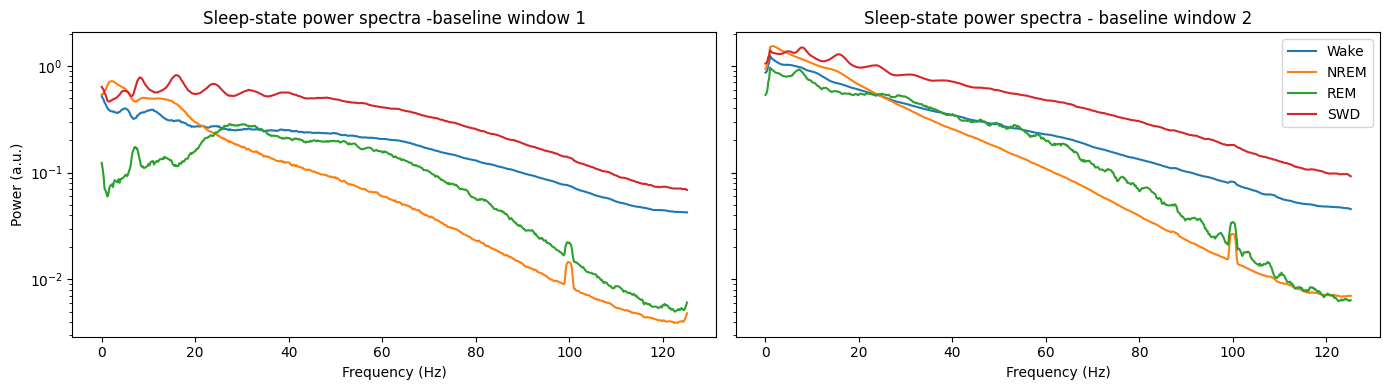

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
state_cols = ["Wake", "NREM", "REM", "SWD"]
for col in state_cols:
    if col in psd_df_bl1.columns:
        axes[0].semilogy(psd_df_bl1["frequency_hz"], psd_df_bl1[col], label=col)
# ax.set_xlim(0, 50)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (a.u.)")
axes[0].set_title("Sleep-state power spectra -baseline window 1")
# axes[0].legend()
for col in state_cols:
    if col in psd_df_bl2.columns:
        axes[1].semilogy(psd_df_bl2["frequency_hz"], psd_df_bl2[col], label=col)
# ax.set_xlim(0, 50)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_title("Sleep-state power spectra - baseline window 2")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Seizure events

Stored as a `pynwbfile.epoch.TimeIntervals` table in
`processing/behavior/seizure_events`, spanning all baseline windows. The table has one
row per seizure event, with `start_time`, `stop_time`, `duration`, and `baseline_window`
columns - split on `baseline_window` to recover the BL1/BL2 subsets used below.

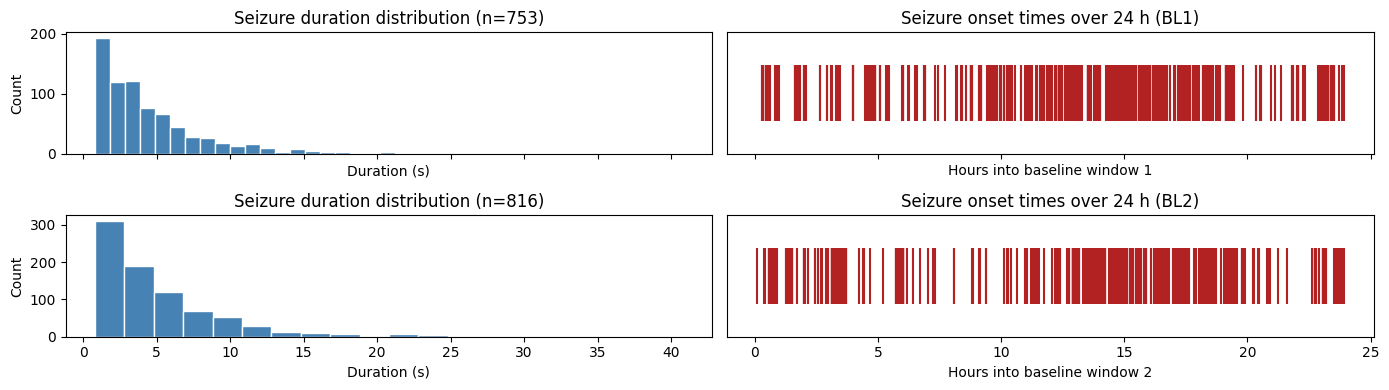

In [21]:
seizure_df = behavior["seizure_events"].to_dataframe()
seizure_df_bl1 = seizure_df[seizure_df["baseline_window"] == "baseline_window_1"]

start_times_bl1 = seizure_df_bl1["start_time"].to_numpy()
stop_times_bl1 = seizure_df_bl1["stop_time"].to_numpy()
durations_bl1 = seizure_df_bl1["duration"].to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(14, 4), sharex="col")

# Duration histogram
axes[0][0].hist(durations_bl1, bins=20, color="steelblue", edgecolor="white")
axes[0][0].set_xlabel("Duration (s)")
axes[0][0].set_ylabel("Count")
axes[0][0].set_title(f"Seizure duration distribution (n={len(durations_bl1)})")

# Event timeline relative to BL1 window start
rel_start_bl1 = (start_times_bl1 - bl1_start_time) / 3600
axes[0][1].eventplot(rel_start_bl1, lineoffsets=0, linelengths=0.5, color="firebrick")
axes[0][1].set_xlabel("Hours into baseline window 1")
axes[0][1].set_yticks([])
axes[0][1].set_title("Seizure onset times over 24 h (BL1)")

seizure_df_bl2 = seizure_df[seizure_df["baseline_window"] == "baseline_window_2"]

start_times_bl2 = seizure_df_bl2["start_time"].to_numpy()
stop_times_bl2 = seizure_df_bl2["stop_time"].to_numpy()
durations_bl2 = seizure_df_bl2["duration"].to_numpy()

# Duration histogram
axes[1][0].hist(durations_bl2, bins=20, color="steelblue", edgecolor="white")
axes[1][0].set_xlabel("Duration (s)")
axes[1][0].set_ylabel("Count")
axes[1][0].set_title(f"Seizure duration distribution (n={len(durations_bl2)})")

# Event timeline relative to BL1 window start
rel_start_bl2 = (start_times_bl2 - bl2_start_time) / 3600
axes[1][1].eventplot(rel_start_bl2, lineoffsets=0, linelengths=0.5, color="firebrick")
axes[1][1].set_xlabel("Hours into baseline window 2")
axes[1][1].set_yticks([])
axes[1][1].set_title("Seizure onset times over 24 h (BL2)")

plt.tight_layout()
plt.show()

In [22]:
seizure_df[:]

,start_time,stop_time,duration,baseline_window
id,,,,
0,73350.3,73353.5,3.2,baseline_window_1
1,73356.7,73363.9,7.2,baseline_window_1
2,73381.3,73386.1,4.8,baseline_window_1
3,73389.1,73394.7,5.6,baseline_window_1
4,73404.1,73406.1,2.0,baseline_window_1
...,...,...,...,...
1564,244432.5,244435.7,3.2,baseline_window_2
1565,244439.7,244440.5,0.8,baseline_window_2
1566,244446.5,244449.7,3.2,baseline_window_2


## 8. EEG/EMG around a seizure event

Pick a seizure by index (`seizure_idx`) from the `seizure_events` table read in Section 7,
and automatically extract +/- `pad_s` seconds of raw EEG/EMG around it for plotting.

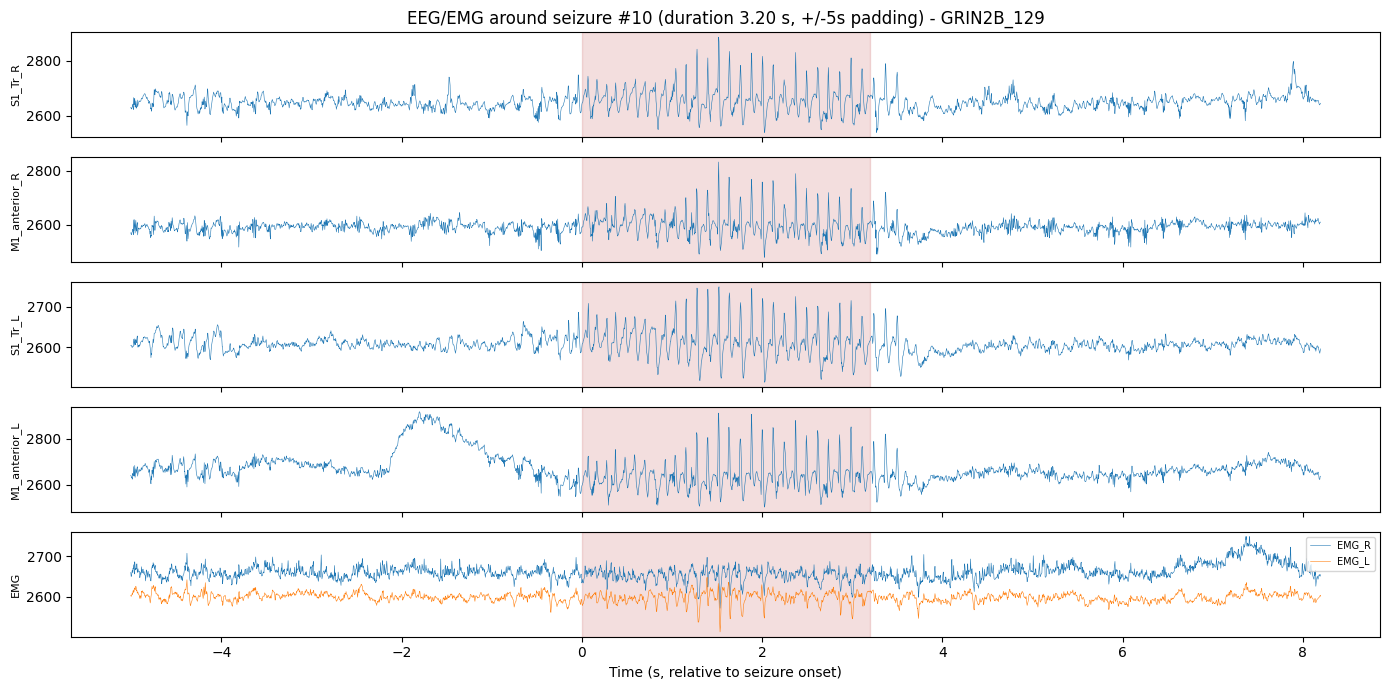

In [23]:
# ── Seizure selection ───────────────────────────────────────────────────────
seizure_idx = 10  # 10th seizure event (0-indexed)
pad_s = 5    # seconds of padding before/after the seizure to include
# ─────────────────────────────────────────────────────────────────────────────

seizure_onset_s = seizure_df["start_time"][seizure_idx]
seizure_offset_s = seizure_df["stop_time"][seizure_idx]

fs = eeg_es.rate

window_start_s = seizure_onset_s - pad_s
window_end_s = seizure_offset_s + pad_s

i_start = int(window_start_s * fs)
i_end = int(window_end_s * fs)
t = np.arange(i_start, i_end) / fs - (seizure_onset_s)  # t=0 at seizure onset

eeg_slice = eeg_es.data[i_start:i_end, :]  # lazy HDF5 read
emg_slice = emg_es.data[i_start:i_end, :]  # lazy HDF5 read

eeg_idx = {"S1_Tr_R": 0, "M1_anterior_R": 3, "S1_Tr_L": 13, "M1_anterior_L": 10}
emg_idx = {"EMG_R": 0, "EMG_L": 1}

fig, axes = plt.subplots(len(eeg_idx) + 1, 1, figsize=(14, 7), sharex=True)

for ax, (label, idx) in zip(axes[:-1], eeg_idx.items()):
    ax.plot(t, eeg_slice[:, idx], lw=0.4)
    ax.set_ylabel(label, fontsize=8)

ax_emg = axes[-1]
for label, idx in emg_idx.items():
    ax_emg.plot(t, emg_slice[:, idx], lw=0.4, label=label)
ax_emg.set_ylabel("EMG", fontsize=8)
ax_emg.legend(fontsize=7, loc="upper right")
ax_emg.set_xlabel("Time (s, relative to seizure onset)")

seizure_duration_s = seizure_offset_s - seizure_onset_s
for ax in axes:
    ax.axvspan(0, seizure_duration_s, color="firebrick", alpha=0.15)

axes[0].set_title(
    f"EEG/EMG around seizure #{seizure_idx} "
    f"(duration {seizure_duration_s:.2f} s, +/-{pad_s}s padding) - GRIN2B_129"
)
plt.tight_layout()
plt.show()

## 9. Per-epoch SWD flags

`swd_epochs` is a `pynwb.epoch.TimeIntervals` table (one row per 5-s epoch) spanning all
baseline windows. Its boolean `is_swd` column is the flag the lab's sleep scorer uses to
label an epoch as SWD, and the `baseline_window` column identifies which baseline window
each row belongs to.

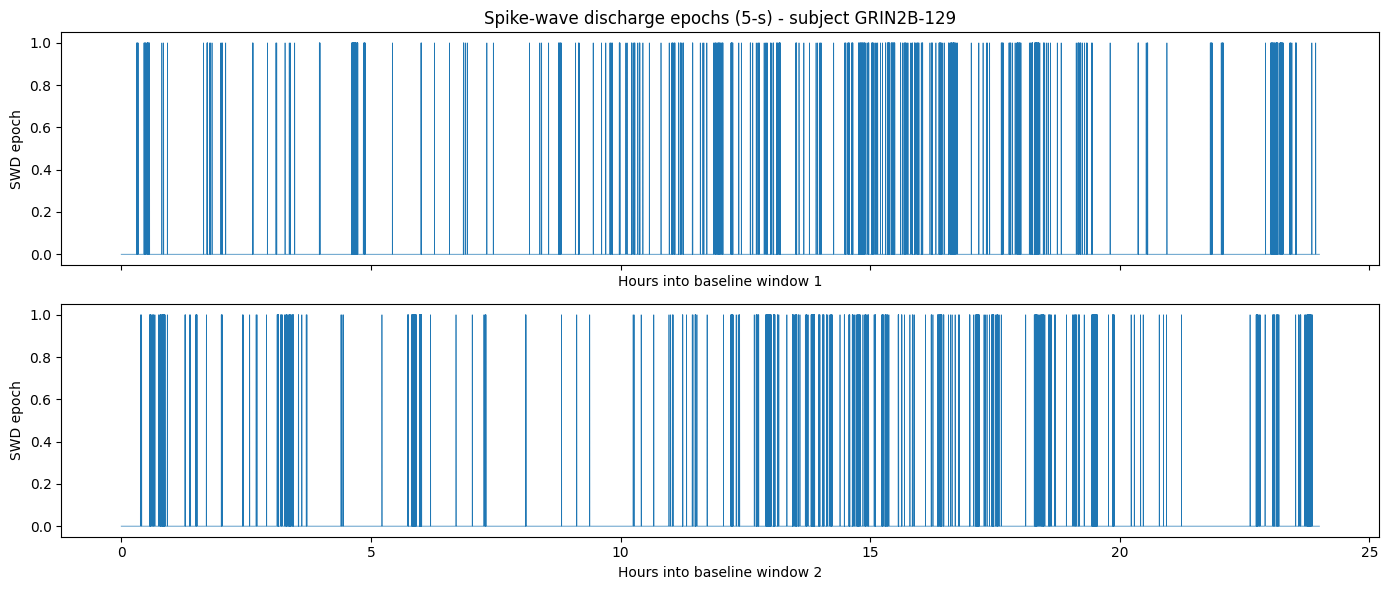

In [24]:
swd_df = behavior["swd_epochs"].to_dataframe()
swd_df_bl1 = swd_df[swd_df["baseline_window"] == "baseline_window_1"]
swd_df_bl2 = swd_df[swd_df["baseline_window"] == "baseline_window_2"]

hours_swd_bl1 = (swd_df_bl1["start_time"] - bl1_start_time) / 3600
hours_swd_bl2 = (swd_df_bl2["start_time"] - bl2_start_time) / 3600

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].plot(hours_swd_bl1, swd_df_bl1["is_swd"].astype(int), lw=0.5)
axes[0].set_xlabel("Hours into baseline window 1")
axes[0].set_ylabel("SWD epoch")
axes[0].set_title(
    f"Spike-wave discharge epochs (5-s) - subject {nwbfile.subject.subject_id}"
)

axes[1].plot(hours_swd_bl2, swd_df_bl2["is_swd"].astype(int), lw=0.5)
axes[1].set_xlabel("Hours into baseline window 2")
axes[1].set_ylabel("SWD epoch")

plt.tight_layout()
plt.show()

In [25]:
# Always close the file when done
#io.close()

## 10. External ontology resources (HERD)

NWB files can carry machine-readable links from metadata values to entities in external
ontologies via HDMF's **HERD** (HDMF External Resources Data), stored in-file under
`/general/external_resources`. Instead of a bare free-text string like `"Rattus norvegicus"`
or `"S1_Tr"`, a HERD reference resolves that value to an unambiguous, resolvable term in a
controlled vocabulary - which is what lets archives like DANDI and other downstream tools
look up "what species / brain region is this, exactly" without guessing.

`neuroconv` writes these references during conversion from the terms listed in the
`ExternalResources` block of the conversion metadata (`grin2b_general_metadata.yaml`); no term is
inferred. In this dataset:

- **Subject species** (`Rattus norvegicus`) → [**NCBI Taxonomy**](https://bioregistry.io/registry/ncbitaxon)
  (`NCBITaxon`), the standard taxonomic identifier system used across biomedical databases.
- **Subject strain** (`Long-Evans`) → [**RRID**](https://bioregistry.io/registry/rrid) of Crl:LE
  (Charles River), the background strain the Grin2b line was made in.
- **Subject genotype** (`Het` only) → RRID of the LE-Grin2bem1Mcwi line. Wild-type littermates
  (`Wt`) carry no engineered allele and have no genotype reference.
- **Electrode / electrode-group `location`** (e.g. `S1_Tr`, `cortex`, `trapezius muscle`) →
  [**UBERON**](https://bioregistry.io/registry/uberon), a cross-species anatomy ontology. The
  per-channel labels are lab acronyms, so each one is mapped to the closest UBERON structure.

`nwbfile.external_resources` is a `HERD` object; calling `.to_dataframe()` flattens it into
one row per `(object, key, entity)` reference.

In [26]:
from IPython.display import HTML

herd = nwbfile.external_resources

if herd is None:
    print("This NWB file has no external resources (ontology annotations).")
else:
    resources_df = herd.to_dataframe()[
        ["object_type", "relative_path", "field", "key", "entity_id", "entity_uri"]
    ].reset_index(drop=True)

    # Render entity_uri as a clickable link so the ontology term can be opened directly
    display_df = resources_df.copy()
    display_df["entity_uri"] = display_df["entity_uri"].apply(
        lambda uri: f'<a href="{uri}" target="_blank">{uri}</a>'
    )
    display(HTML(display_df.to_html(escape=False, index=False)))

object_type,relative_path,field,key,entity_id,entity_uri
Subject,species,,Rattus norvegicus,NCBITaxon:10116,http://purl.obolibrary.org/obo/NCBITaxon_10116
Subject,strain,,Long-Evans,RRID:RGD_2308852,https://scicrunch.org/resolver/RRID:RGD_2308852
Subject,genotype,,Het,RRID:RGD_14394515,https://scicrunch.org/resolver/RRID:RGD_14394515
VectorData,,,S1_Tr,UBERON:0008933,http://purl.obolibrary.org/obo/UBERON_0008933
VectorData,,,M2_Fra,UBERON:0016634,http://purl.obolibrary.org/obo/UBERON_0016634
VectorData,,,M2_anterior,UBERON:0016634,http://purl.obolibrary.org/obo/UBERON_0016634
VectorData,,,M1_anterior,UBERON:0001384,http://purl.obolibrary.org/obo/UBERON_0001384
VectorData,,,V2_ML,UBERON:0022232,http://purl.obolibrary.org/obo/UBERON_0022232
VectorData,,,V1_M,UBERON:0002436,http://purl.obolibrary.org/obo/UBERON_0002436
VectorData,,,S1Hl_S1Fl,UBERON:0008933,http://purl.obolibrary.org/obo/UBERON_0008933


### Referenced ontologies

Each `entity_id` is a CURIE (`PREFIX:local_id`), e.g. `NCBITaxon:10116` or `UBERON:0008933`.
The prefix identifies which ontology the term comes from. The cell below inspects the
prefixes actually present in this file and prints a clickable link to each ontology's
registry page (via [Bioregistry](https://bioregistry.io/), a registry of ontology
namespaces), along with a short description.

In [27]:
# Short descriptions of the ontologies whose prefixes may appear in entity_id
ONTOLOGY_INFO = {
    "NCBITaxon": ("NCBI Taxonomy", "Taxonomic identifiers (species) used across biomedical databases."),
    "UBERON": ("Uberon", "Cross-species anatomy ontology covering organs and gross anatomical structures."),
    "MBA": ("Allen Mouse Brain Atlas", "Structure ontology for the mouse brain."),
    "HBA": ("Allen Human Brain Atlas", "Structure ontology for the human brain."),
    "RRID": ("Research Resource Identifiers", "Identifiers for research resources, e.g. animal strains and antibodies."),
}

if herd is not None and not resources_df.empty:
    prefixes = sorted({entity_id.split(":")[0] for entity_id in resources_df["entity_id"]})

    rows = []
    for prefix in prefixes:
        name, description = ONTOLOGY_INFO.get(prefix, (prefix, ""))
        url = f"https://bioregistry.io/registry/{prefix.lower()}"
        rows.append(
            f'<li><a href="{url}" target="_blank"><b>{name}</b></a> '
            f'(<code>{prefix}</code>) - {description}</li>'
        )

    display(HTML("<ul>" + "".join(rows) + "</ul>"))